In [3]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
from cartopy import crs as ccrs
import dask
import rioxarray
from dask.distributed import Client
from dask_jobqueue import PBSCluster
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:

# Setup your PBSCluster
cluster = PBSCluster(
    cores=4,  # Total number of cores across all processes
    memory='100GB',  # Memory per worker
    processes=4,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=4:mem=100GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='6:00:00')

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [5]:
client

<Client: 'tcp://128.117.208.207:35273' processes=4 threads=4, memory=93.12 GiB>

## Custom colour map

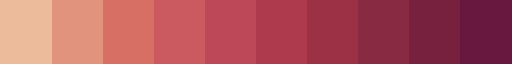

In [6]:
from matplotlib.colors import LinearSegmentedColormap
combined_colors = ['#ecbb9b','#da7467','#c34e5c','#a9354a','#842940','#68173e']
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)
cmap1 = create_gradient_colormap(10,combined_colors)
cmap1

## Map plotting function

In [7]:
def plot_simulated(llon, llat, prec, row, col, levs, cmap1, shape_feature, ax1):
    import cartopy.io.shapereader as shpreader

    g = ax1.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.4, linestyle='--')
    g.xlines = g.ylines = False

    #ax1.set_xticks(np.arange(-112, -105, 2), crs=ccrs.PlateCarree())
    #ax1.set_yticks(np.arange(35, 44.1, 1), crs=ccrs.PlateCarree())
    #ax1.tick_params(axis='both', which='major', direction='out', length=3.5, width=0.8, labelsize=8.5, color='k')
    #ax1.tick_params(labelbottom=(row == 0), bottom=(row == 0))
    #ax1.tick_params(labelleft=(col == 0), left=(col == 0))

    pc1 = ax1.contourf(llon, llat, prec, cmap=cmap1, transform=ccrs.PlateCarree(), levels=levs,extend='max')

    reader = shpreader.Reader(shape_feature)
    for geom in reader.geometries():
        boundary = geom.boundary
        lines = boundary.geoms if boundary.geom_type == "MultiLineString" else [boundary]
        for line in lines:
            ax1.add_geometries([line], crs=ccrs.PlateCarree(), edgecolor="#525252",
                                facecolor="none", linewidth=1, zorder=1)

    return pc1

## Heatwave attribute functions

In [8]:
from itertools import groupby

def heatwave_attributes(temps , threshold, n_days):
    heatwave_days = temps > threshold
    heatwave_rle  = [(value, sum(1 for _ in group)) for value, group in groupby(heatwave_days)]

    mean_intensities, durations, max_intensities, max_dates = [], [], [], []

    start_idx = 0
    for value, length in heatwave_rle:
        end_idx = start_idx + length - 1
        if value and length >= n_days:
            hw_temps = temps[start_idx:end_idx + 1]
            mean_intensities.append(np.mean(hw_temps))
            durations.append(length)
            max_intensities.append(np.max(hw_temps))
            max_dates.append(np.argmax(hw_temps) + start_idx)
        start_idx = end_idx + 1

    if not mean_intensities:
        return [np.nan]*6

    return [
        len(mean_intensities),
        np.max(durations),
        np.mean(durations),
        np.max(max_intensities),
        np.mean(mean_intensities),
        max_dates[np.argmax(max_intensities)],
    ]


def process_grid(df_np, time_list, n_days, threshold_q):
    df = xr.DataArray(df_np, dims=['time'], coords={'time': time_list}) 

    df_th      = df.sel(time=slice('1950-01-01', '2020-12-31'))
    doy_thresh = df_th.groupby('time.dayofyear').quantile(threshold_q, dim='time')
    threshold  = doy_thresh.sel(dayofyear=df['time'].dt.dayofyear).values 

    years       = np.unique(time_list.dt.year)
    result_list = []                                                        
    for year in years:                                                      
        mask      = (time_list.dt.year == year).values
        temps_yr  = df_np[mask]
        thresh_yr = threshold[mask]
        #hw_days   = temps_yr > thresh_yr
        result_list.append(heatwave_attributes(temps_yr,thresh_yr,  n_days)) 

    return np.array(result_list, dtype=np.float64)    


## Load ERA5 daily maximum temperature

In [9]:
ds = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/era5.tmax.1940-2024.nc')
ds = dask.compute(ds)[0]

## Calculate annual heatwave attributes

In [10]:
months     = [5, 6]
start_year = '1950'
end_year   = '2024'

ds_clim = (ds['VAR_2T']
          .sel(time=ds['VAR_2T'].time.dt.month.isin(months))
          .sel(time=slice(start_year + '-01-01', end_year + '-12-31')))

chunks    = {'time': -1, 'latitude': 50, 'longitude': 50}
dataarray = ds_clim - 273.15

attributes  = ['frequency', 'overall_max_duration', 'overall_mean_duration',
              'overall_max_intensity', 'overall_mean_intensity',
              'date_max_intensity']
time_len    = len(np.unique(dataarray.time.dt.year))
threshold_q = 0.9
n_days      = 3

result = xr.apply_ufunc(
    process_grid,
    dataarray.chunk(chunks),
    input_core_dims=[["time"]],  
    output_core_dims=[["year","attributes"]],  
    vectorize=True,  
    kwargs={"n_days": n_days, 'time_list': dataarray.time, "threshold_q": threshold_q},  
    dask="parallelized",
    output_dtypes=[np.float64], 
    dask_gufunc_kwargs={'output_sizes': {"year":time_len, "attributes": len(attributes)}}
)

result = result.assign_coords({'attributes': attributes, 'year': np.unique(dataarray.time.dt.year)})
result = dask.compute(result)[0]

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/distributed/client.py:3164: UserWarning: Sending large graph of size 1.03 GiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


## Plot the 2024 heatwave intensity map

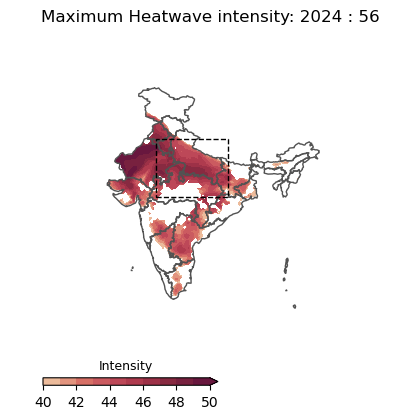

In [11]:
import matplotlib.patches as patches
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
gdf = gpd.read_file(shp_file)



# ── Plot 2: Heatwave intensity map for 2024 ───────────────────────────────────
f = plt.figure(figsize=(5, 5))
gs1 = gridspec.GridSpec(1, 1)
gs1.update(left=0.099, bottom=0.14, wspace=0.002, hspace=0.16)

gdf = gpd.read_file(shp_file)

levs   = np.arange(40, 50.1, 1)
c1diff = cmap1   # your custom colormap from earlier

ax1 = f.add_subplot(gs1[0, 0], projection=ccrs.PlateCarree())
data = result.sel(attributes='overall_max_intensity').sel(year=2024)
data = data.rio.write_crs("EPSG:4326").rio.clip(gdf.geometry, gdf.crs, drop=True)
pc   = plot_simulated(data.longitude, data.latitude, data, 0, 0, levs, c1diff, shp_file, ax1)

plt.title(f"Maximum Heatwave intensity: 2024 : {''.join(map(str, months))}")


cbar_ax = f.add_axes([0.165, 0.09, 0.35, 0.015])
cb = plt.colorbar(pc, cax=cbar_ax, orientation="horizontal",extend='both')
#cb.ax.tick_params(labelsize=8)
cb.ax.set_title('Intensity', fontsize=9)
ax1.spines['geo'].set_visible(False) 
ax1.set_xlim([55,110])
ax1.set_ylim([5,45])
ax1.set_xticks([])
#rectangle1 = patches.Rectangle((70, 22), 5, 8, edgecolor='b', facecolor='none', linewidth=1, linestyle='--')
rectangle2 = patches.Rectangle((75, 22), 10, 8, edgecolor='k', facecolor='None', linewidth=1, linestyle='--')
#ax1.add_patch(rectangle1)
ax1.add_patch(rectangle2)

#plt.savefig("Heatwave_duration.pdf", dpi=300, transparent=True)
plt.show()

## Plot regional intensity for 75–85°E, 22–30°N

/glade/derecho/scratch/adixit/tmp/ipykernel_129267/3143209741.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(np.arange(1940,2024,10))
/glade/derecho/scratch/adixit/tmp/ipykernel_129267/3143209741.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_yticklabels([str(np.round(t+data.mean().item(),2)) for t in ax1.get_yticks()])


[Text(0, -3.0, '44.03'),
 Text(0, -2.0, '45.03'),
 Text(0, -1.0, '46.03'),
 Text(0, 0.0, '47.03'),
 Text(0, 1.0, '48.03'),
 Text(0, 2.0, '49.03'),
 Text(0, 3.0, '50.03')]

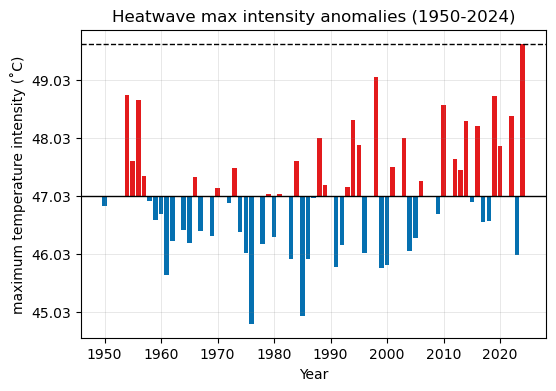

In [12]:
f = plt.figure(figsize=(6,4))
gs1 = gridspec.GridSpec(1,1)
ax1 = f.add_subplot(gs1[0,0])

attr_name='overall_max_intensity'
ds_attr = result.sel(longitude=slice(75,85),latitude=slice(30,22)).sel(attributes=attr_name)

nan_frac = ds_attr.isnull().mean(dim=("latitude", "longitude"))
da_out = xr.where(nan_frac > 0.8, np.nan, ds_attr)

data = da_out.max(dim=['latitude','longitude'])
data_anom = data-data.mean()
ax1.bar(x=np.arange(len(data)),height=data_anom)
x = np.arange(len(data_anom))

c1 = '#e31a1c'
c2 = '#0570b0'
colors = [c1 if val > 0 else c2 for val in data_anom]

plt.bar(x=x, height=data_anom, color=colors)

ax1.set_xlabel("Year")
ax1.set_ylabel("maximum temperature intensity (˚C)")
ax1.set_title("Heatwave max intensity anomalies (1950-2024)")
ax1.axhline(y=data_anom[-1], lw=1, color='k', linestyle='--')
ax1.axhline(y=0, lw=1, color='k', linestyle='-')
ax1.grid(True, which='both', linestyle='-', linewidth=0.5, color='gray', alpha=0.25)
ax1.set_xticklabels(np.arange(1940,2024,10))
ax1.set_yticklabels([str(np.round(t+data.mean().item(),2)) for t in ax1.get_yticks()])

#plt.savefig("R2-heatwave.pdf",dpi=300,format='pdf',transparent=True)